# 국제시장권 | 쇼핑 밀집형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, CASE_COMPARISONS, STAY_CASES, TIME_FIGURES,
                      plot_case_comparison, plot_stay_case, plot_time_weekday)
CASE = '국제시장권'


## 이동·체류와 비교 기준

,지표,비교 대상,값,단위
0,쇼핑여가 목적 도착 OD,국제시장권,40.70,%
1,쇼핑여가 목적 도착 OD,전국 평균,5.90,%
2,주말/평일 일평균 도착,국제시장권,1.66,배
3,주말/평일 일평균 도착,전국 평균,1.03,배
4,해당 시장 행정동 도착 비중,국제시장권,22.70,%
5,해당 시장 행정동 도착 비중,전국 평균,16.30,%


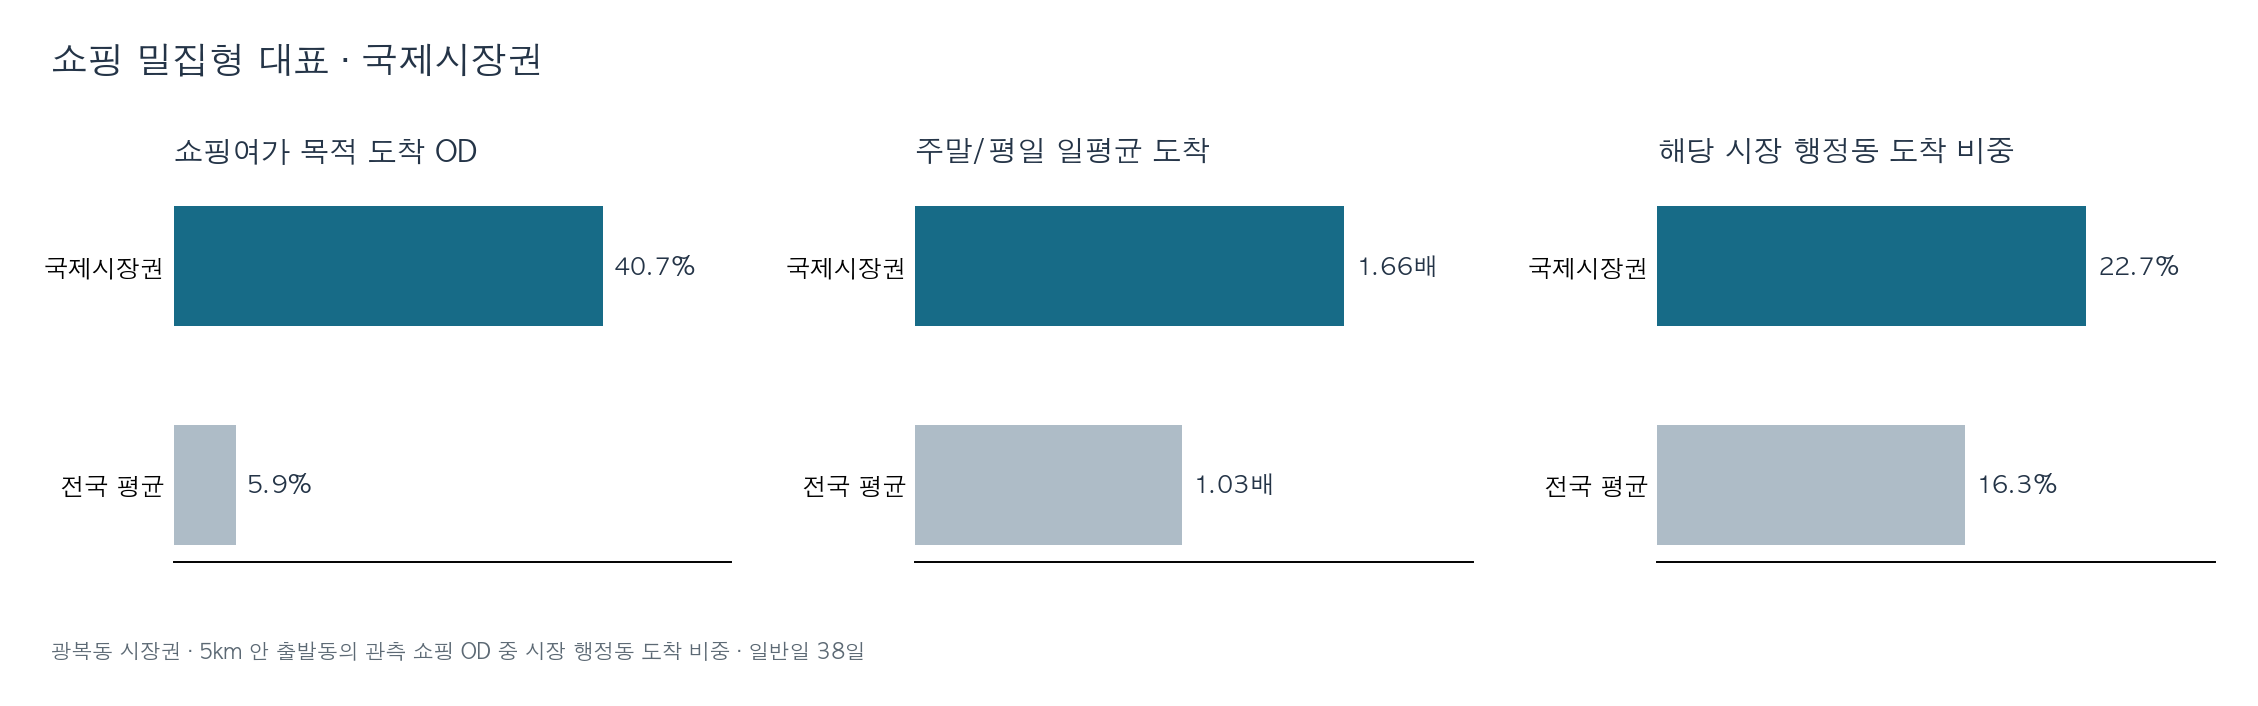

In [2]:
filename, title, panels, note = CASE_COMPARISONS[CASE]
comparison = pd.DataFrame([
    {"지표": metric, "비교 대상": name, "값": value, "단위": unit}
    for metric, names, values, unit in panels
    for name, value in zip(names, values)
])
display(comparison)
plot_case_comparison(CASE)
display(Image(filename=str(FIGS / filename)))

## 체류 구성

In [ ]:
stay = STAY
selected = stay.loc[stay["case"].eq(CASE),
                    ["metric", "case_share", "national_market_row_mean", "scope"]].copy()
selected[["case_share", "national_market_row_mean"]] *= 100
display(selected.rename(columns={"case_share":"사례 (%)",
                                  "national_market_row_mean":"전국 시장 행 평균 (%)"}))
plot_stay_case(CASE)
display(Image(filename=str(FIGS / STAY_CASES[CASE][0])))

## 시간·요일별 분포

,measure,daytype,정점 시각,시간별 구성비 (%)
69,쇼핑여가 목적 도착 OD,주말,14,13.2
87,쇼핑여가 목적 도착 OD,평일,18,12.2
98,쇼핑여가 목적 체류 STAY,주말,15,12.7
110,쇼핑여가 목적 체류 STAY,평일,13,10.9


,measure,day_of_week,요일별 구성비 (%),observed_days
14,쇼핑여가 목적 도착 OD,0,10.8,4
15,쇼핑여가 목적 도착 OD,1,9.3,5
16,쇼핑여가 목적 도착 OD,2,10.3,6
17,쇼핑여가 목적 도착 OD,3,11.3,5
18,쇼핑여가 목적 도착 OD,4,12.3,6
19,쇼핑여가 목적 도착 OD,5,21.8,6
20,쇼핑여가 목적 도착 OD,6,24.2,6
21,쇼핑여가 목적 체류 STAY,0,12.1,4
22,쇼핑여가 목적 체류 STAY,1,10.0,5
23,쇼핑여가 목적 체류 STAY,2,10.7,6


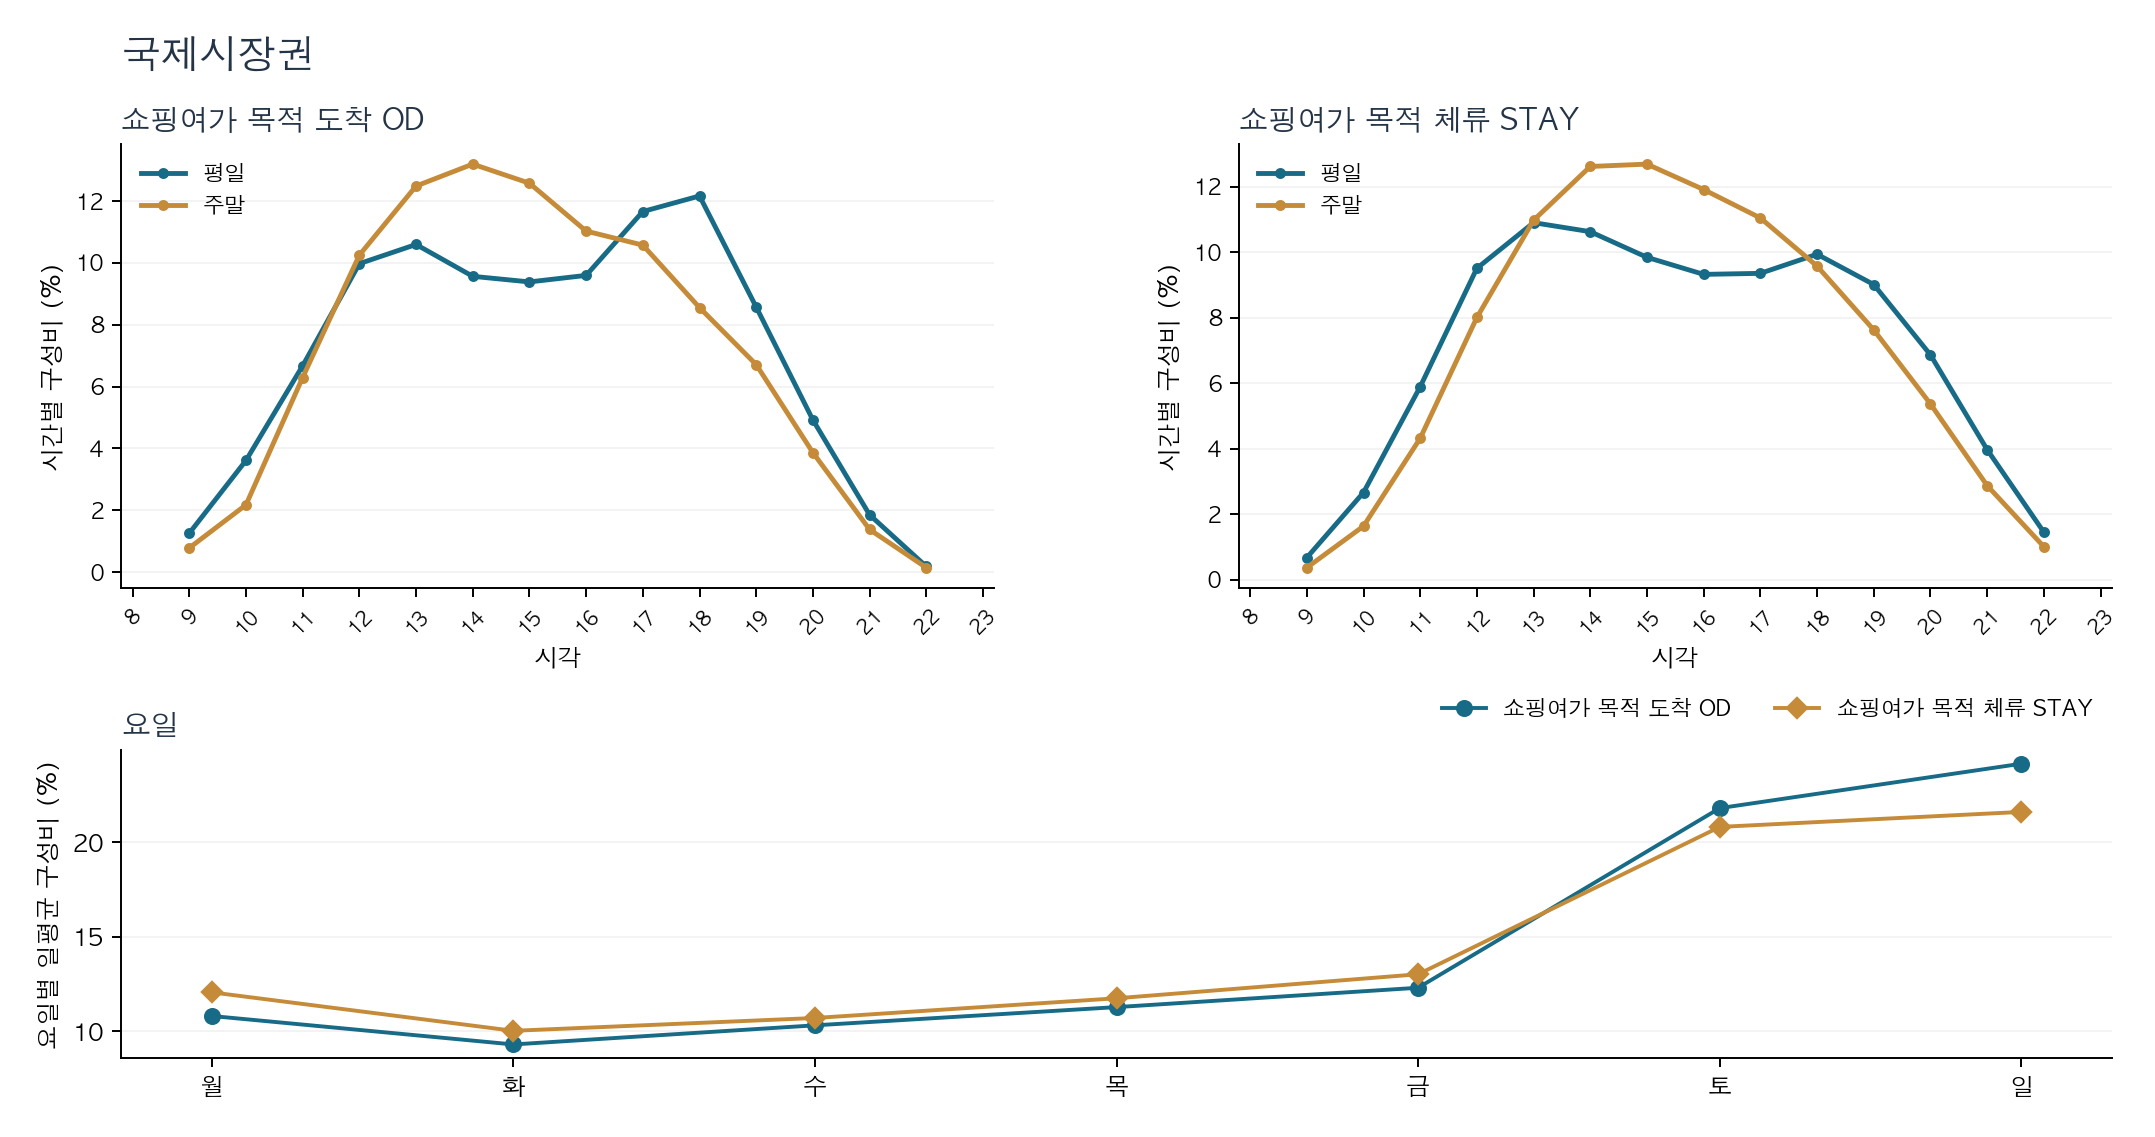

In [4]:
hourly = HOUR.loc[HOUR["case"].eq(CASE)].copy()
peaks = hourly.loc[hourly.groupby(["measure", "daytype"])["hour_share"].idxmax(),
                   ["measure", "daytype", "hour", "hour_share"]].copy()
peaks["hour_share"] = (peaks["hour_share"] * 100).round(1)
display(peaks.rename(columns={"hour":"정점 시각", "hour_share":"시간별 구성비 (%)"}))
weekday = WEEK.loc[WEEK["case"].eq(CASE)].copy()
weekday["요일별 구성비 (%)"] = weekday.groupby("measure")["daily_index"].transform(
    lambda values: values / values.sum() * 100
).round(1)
display(weekday[["measure", "day_of_week", "요일별 구성비 (%)", "observed_days"]])
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 주변 조건

* 그림: 비공개 시설·공간 입력으로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시장 위치 입력이 없어 저장된 지도를 표시합니다.


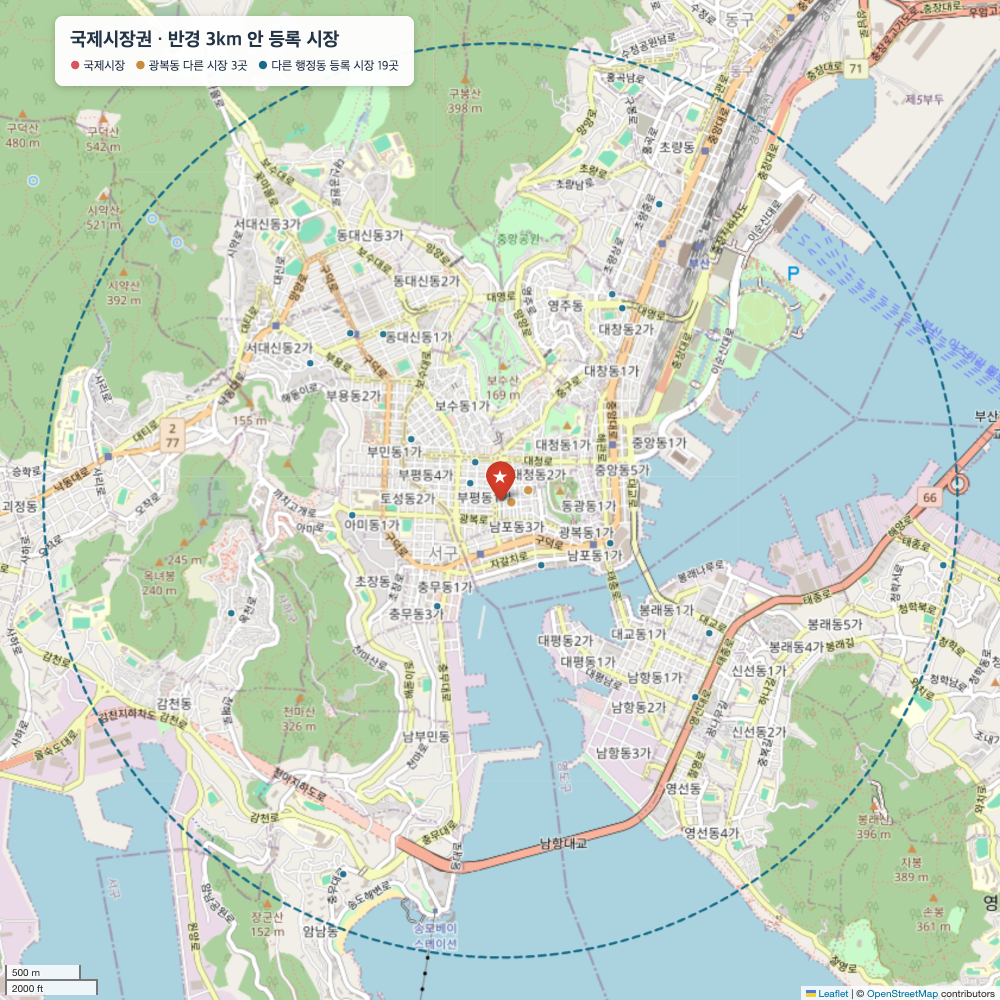

In [5]:
import os, tempfile
from plotting import international, render_map_png
features_path = os.environ.get("BC_MARKET_FEATURES")
figure_path = Path("../figs") / "fig_v4_4b_international_nearby.png"
if features_path and Path(features_path).exists():
    features = pd.read_csv(features_path, dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = international(features, Path(folder))
        render_map_png(map_html, FIGS / "fig_v4_4b_international_nearby.png", 1000, 1000)
    figure_path = FIGS / "fig_v4_4b_international_nearby.png"
else:
    print("비공개 시장 위치 입력이 없어 저장된 지도를 표시합니다.")
display(Image(filename=str(figure_path)))

## 제안

* 방안: 광복동 4개 시장의 공동 지도·쿠폰과 동선 안내 시범 검토
* 상태: 시행·효과 미확인